### **K-Nearest Neighbors (KNN)**

**Type**: Classification and Regression 

**Definition**: Predicts using the closest training data points (nearest neighbours).  
    
( Pudhu data-ku pakkathula irukkura similar data points-a compare panni predict pannum)  
    
Example: Classifying a new fruit by comparing its features with nearby examples of apples and oranges.  

In [73]:
import pandas as pd
telescope_data =pd.read_csv("C:\\techpanda\\course\\ML\\data\\telescope_data.csv")
telescope_data.head()

,Unnamed: 0,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


In [74]:
telescope_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 19020 entries, 0 to 19019
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  19020 non-null  int64  
 1   fLength     19020 non-null  float64
 2   fWidth      19020 non-null  float64
 3   fSize       19020 non-null  float64
 4   fConc       19020 non-null  float64
 5   fConc1      19020 non-null  float64
 6   fAsym       19020 non-null  float64
 7   fM3Long     19020 non-null  float64
 8   fM3Trans    19020 non-null  float64
 9   fAlpha      19020 non-null  float64
 10  fDist       19020 non-null  float64
 11  class       19020 non-null  str    
dtypes: float64(10), int64(1), str(1)
memory usage: 1.7 MB


In [75]:
telescope_data.describe()

,Unnamed: 0,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist
count,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000
mean,9509.500000,53.250154,22.180966,2.825017,0.380327,0.214657,-4.331745,10.545545,0.249726,27.645707,193.818026
std,5490.745396,42.364855,18.346056,0.472599,0.182813,0.110511,59.206062,51.000118,20.827439,26.103621,74.731787
min,0.000000,4.283500,0.000000,1.941300,0.013100,0.000300,-457.916100,-331.780000,-205.894700,0.000000,1.282600
25%,4754.750000,24.336000,11.863800,2.477100,0.235800,0.128475,-20.586550,-12.842775,-10.849375,5.547925,142.492250
50%,9509.500000,37.147700,17.139900,2.739600,0.354150,0.196500,4.013050,15.314100,0.666200,17.679500,191.851450
75%,14264.250000,70.122175,24.739475,3.101600,0.503700,0.285225,24.063700,35.837800,10.946425,45.883550,240.563825
max,19019.000000,334.177000,256.382000,5.323300,0.893000,0.675200,575.240700,238.321000,179.851000,90.000000,495.561000


In [76]:
telescope_data.shape

(19020, 12)

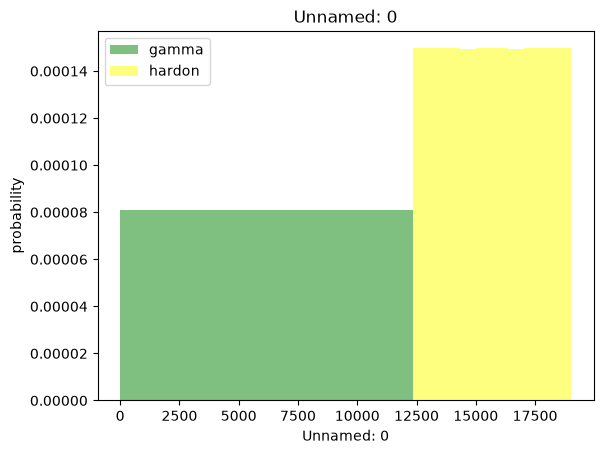

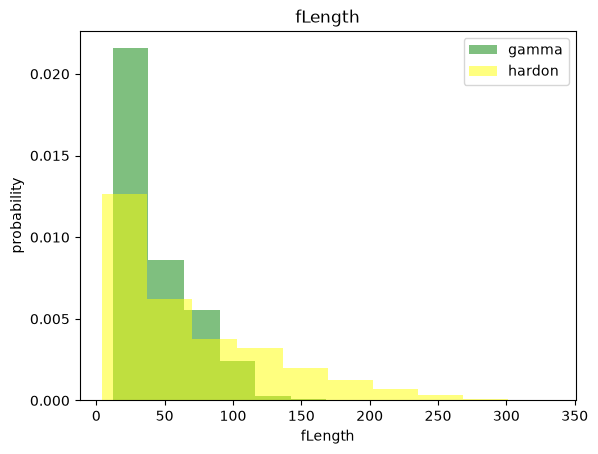

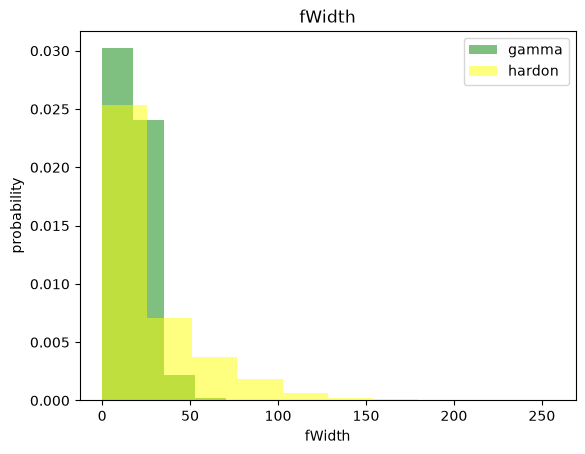

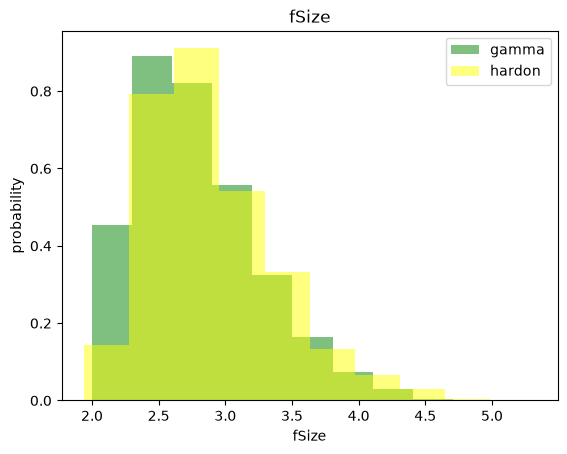

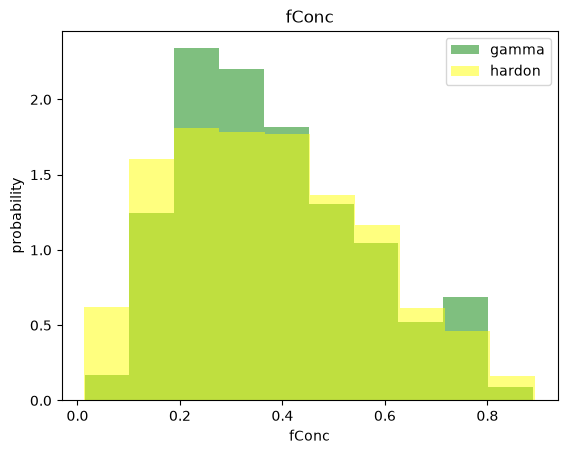

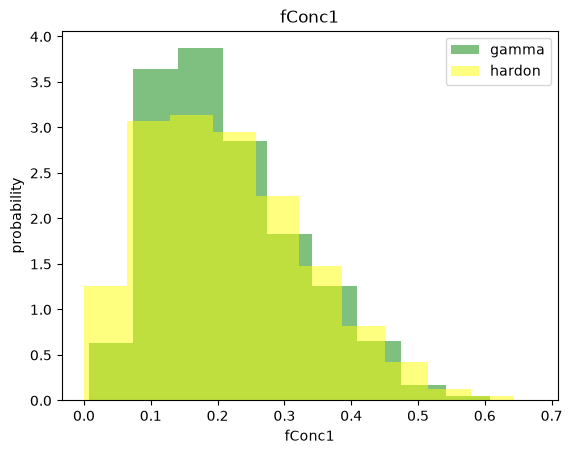

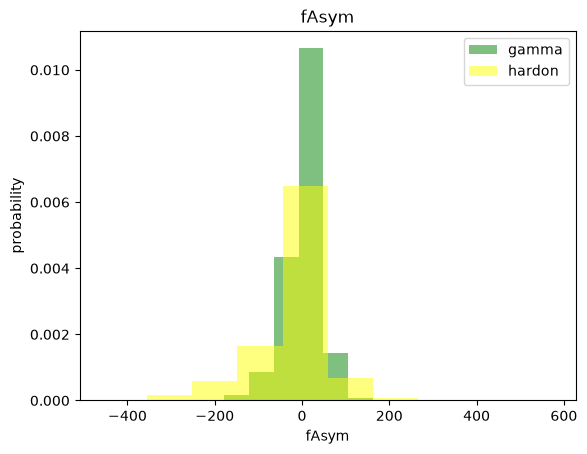

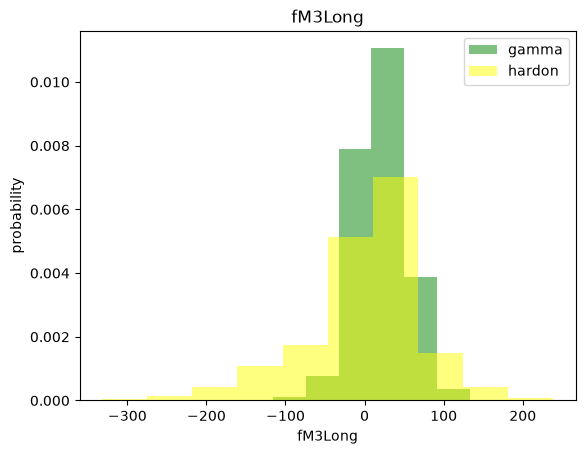

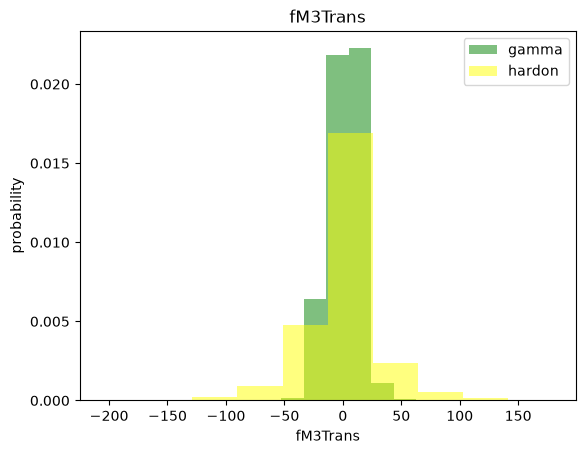

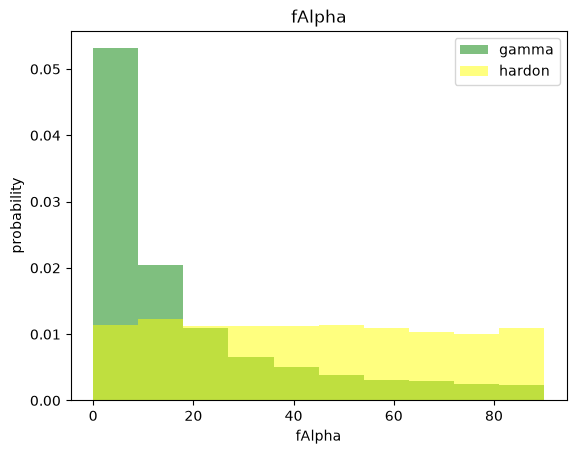

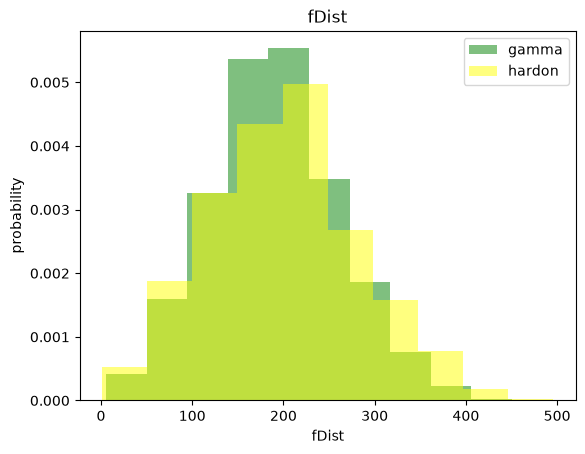

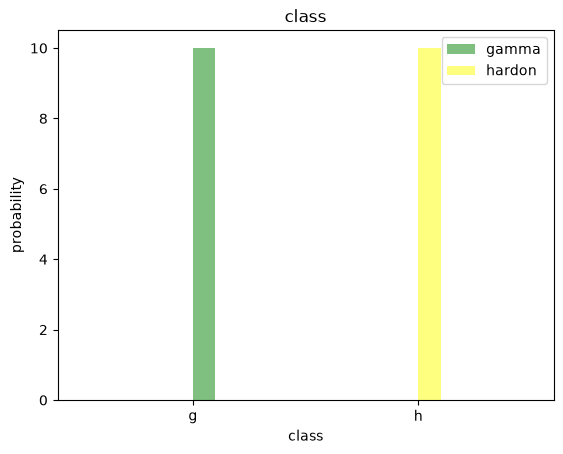

In [77]:
import matplotlib.pyplot as plt
for label in (telescope_data.columns):
    #density=True--to diplay the probabilityxxxxx
    plt.hist(telescope_data[telescope_data['class']=='g'][label],color='green',label='gamma',alpha=0.5,density=True)
    plt.hist(telescope_data[telescope_data['class']=='h'][label],color='yellow',label='hardon',alpha=0.5,density=True)
    
    plt.title(label)
    plt.xlabel(label)
    plt.ylabel("probability")
   
    plt.legend()
    plt.show();
    

In [78]:
from sklearn.model_selection import train_test_split

ds_train, ds_test = train_test_split(telescope_data, test_size=0.2)


In [89]:
print(len(ds_train))
print(len(ds_test))
# this is over all  tarin and test data in original dataset

15216
3804


In [90]:
print(len(ds_train[ds_train['class']=='g']))
print(len(ds_train[ds_train['class']=='h']))

9856
5360


In [92]:
from imblearn.over_sampling import RandomOverSampler
#randomoversampler used to  change balance data from imbalance

r_ram = RandomOverSampler()

#tarin data input and output
input_ds_train = ds_train.drop(columns=['class'])
output_ds_train = ds_train['class']
print(input_ds_train)

       Unnamed: 0   fLength   fWidth   fSize   fConc  fConc1     fAsym  \
13566       13566  167.6880  55.4209  3.4801  0.3354  0.1717 -114.5980   
7270         7270   26.0427  13.9789  2.4378  0.4234  0.2464   25.5144   
13534       13534  175.0354  24.5739  2.7976  0.4578  0.2373 -156.9173   
17683       17683   18.4805  15.7443  2.6032  0.3722  0.2168   12.7537   
15253       15253   44.4822  38.1900  2.6882  0.3310  0.1824   -7.8757   
...           ...       ...      ...     ...     ...     ...       ...   
18162       18162  139.7989  90.8769  3.6631  0.1837  0.1067 -115.1394   
16649       16649   26.9052  12.1550  2.5259  0.4869  0.2473   -2.6010   
17245       17245   18.5949  10.0448  2.3563  0.5466  0.3201   20.2303   
4968         4968   63.4209  26.9573  3.0955  0.2063  0.1152   46.6222   
12161       12161   12.8768  11.4371  2.0917  0.7368  0.3765   15.0655   

        fM3Long  fM3Trans   fAlpha     fDist  
13566 -166.1910   52.9735  46.2067  327.2450  
7270    21.9824  

In [93]:
print(output_ds_train )

13566    h
7270     g
13534    h
17683    h
15253    h
        ..
18162    h
16649    h
17245    h
4968     g
12161    g
Name: class, Length: 15216, dtype: str


In [99]:
from sklearn.preprocessing import StandardScaler

obj_scaler = StandardScaler()

# fit() –  to calculateMean and Standard Deviation  .
# transform() – to  convert  Original values to standardized values.

input_ds_train  = obj_scaler.fit_transform(input_ds_train)
#KNN calculates the distance between data points to identify the nearest neighbours.

In [100]:
print(input_ds_train )

[[ 0.7349358   2.69296658  1.79108563 ...  2.52243295  0.71443817
   1.78707546]
 [-0.41409491 -0.63998542 -0.4423733  ... -0.36904967  0.14764092
   0.15512898]
 [ 0.72909575  2.86585288  0.12862948 ...  0.44694945 -0.38135244
   0.24485086]
 ...
 [ 1.40635956 -0.81523415 -0.65439615 ... -0.4621064   1.17496838
  -0.02309145]
 [-0.83421383  0.23953368  0.25707951 ... -0.97526226 -1.02947392
   1.15806692]
 [ 0.47852091 -0.94978258 -0.57936008 ...  0.54775373 -0.39306178
  -1.31718836]]


In [101]:
# here resampler is use to balance the values(gama and hardon) like before gama=300 ,hardon=200,
#after gama=300 ,hardon=300,
input_ds_train,output_ds_train = r_ram.fit_resample(input_ds_train,output_ds_train)
print(len(output_ds_train))
print(sum(output_ds_train == 'g'))  # Gamma records count.
print(sum(output_ds_train == 'h'))  # Hadron records count

19712
9856
9856


In [102]:
# Prepare Testing Data
# here ouput is class

input_ds_test = ds_test.drop(columns=['class'])
output_ds_test = ds_test['class']


input_ds_test = obj_scaler.transform(input_ds_test)
input_ds_test

C:\Users\Admin\miniconda3\envs\baby\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


array([[ 6.712000e+03,  3.025730e+01,  1.268290e+01, ...,  7.175000e+00,
         2.986500e+01,  1.532070e+02],
       [ 6.331000e+03,  8.000320e+01,  2.122660e+01, ...,  1.343330e+01,
         9.041000e+00,  3.034670e+02],
       [ 1.637200e+04,  2.976310e+01,  2.000000e-04, ...,  2.189780e+01,
         2.871600e+01,  2.073690e+02],
       ...,
       [ 1.840300e+04,  6.570250e+01,  1.132380e+01, ..., -8.068900e+00,
         2.136270e+01,  2.405631e+02],
       [ 1.076000e+03,  5.564620e+01,  1.999460e+01, ..., -1.781000e+01,
         1.515100e+01,  2.742920e+02],
       [ 1.163300e+04,  5.570650e+01,  1.878980e+01, ..., -1.718320e+01,
         5.801000e+00,  2.102720e+02]], shape=(3804, 11))

In [103]:
print(len(input_ds_test))

3804


In [104]:
from sklearn.neighbors import KNeighborsClassifier

Knn_model = KNeighborsClassifier(n_neighbors=2)

Knn_model.fit(input_ds_train, output_ds_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",2
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['g','h']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [107]:
output_pred = Knn_model.predict(input_ds_test)
output_pred

array(['h', 'h', 'h', ..., 'h', 'h', 'h'], shape=(3804,), dtype=object)

In [112]:
from sklearn.metrics import accuracy_score
accuracy_info = accuracy_score(output_ds_test,output_pred )
accuracy_info

0.3491062039957939